In [2]:
pip install pandas numpy scikit-learn matplotlib seaborn jupyter

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/6 [webcolors]
   ------ --------------------------------- 1/6 [uri-template]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   -------------------------- ------------- 4/6 [rfc3987-syntax]
   --------------------------------- ------ 5/6 [isoduration]
   --------------------------------- ------ 5/6 [isoduration]
   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [iso

In [ ]:
df = pd.read_csv('forestfires.csv')

In [6]:
df.head()
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


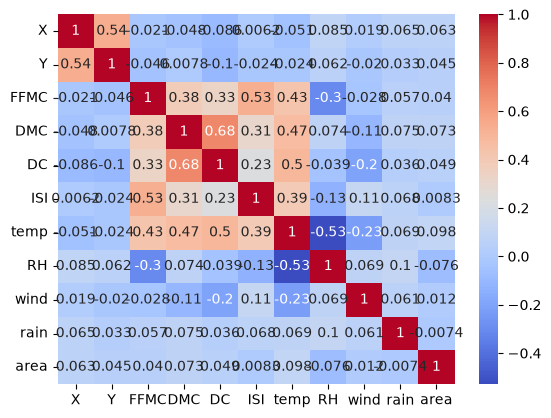

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
matrice_correlation = df.corr(numeric_only=True)

sns.heatmap(matrice_correlation, annot=True, cmap='coolwarm')
plt.show()

Score d'asymétrie original : 12.85


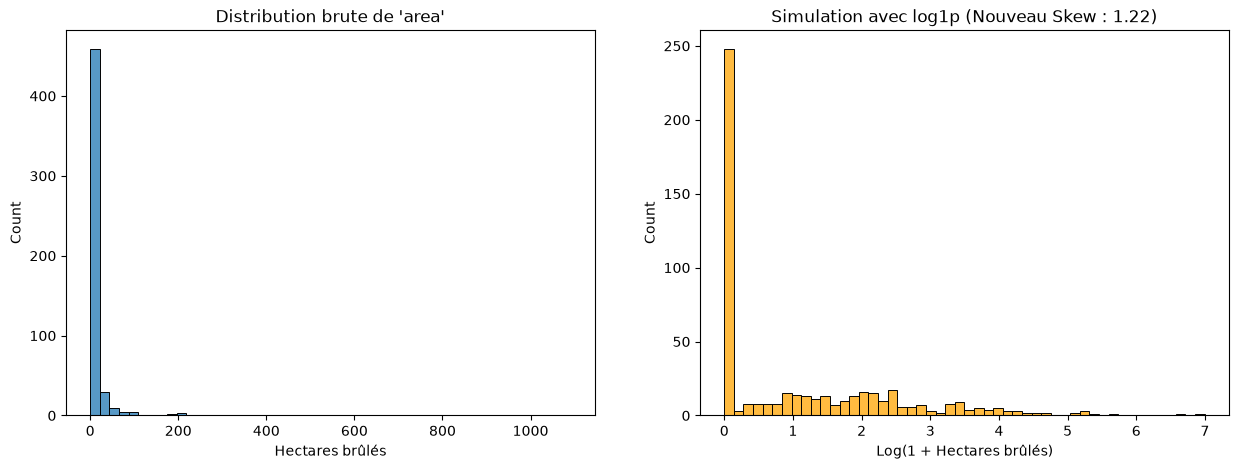

In [13]:
import numpy as np

# distribution skeewed ?
skew_original = df['area'].skew()
print(f"Score d'asymétrie original : {skew_original:.2f}")


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique de gauche : Les données brutes
sns.histplot(df['area'], bins=50, ax=axes[0])
axes[0].set_title("Distribution brute de 'area'")
axes[0].set_xlabel("Hectares brûlés")

# Graphique de droite : Simulation avec la transformation Log
# sans modificaiton du dataframe
area_log_simule = np.log1p(df['area'])
sns.histplot(area_log_simule, bins=50, ax=axes[1], color='orange')
axes[1].set_title(f"Simulation avec log1p (Nouveau Skew : {area_log_simule.skew():.2f})")
axes[1].set_xlabel("Log(1 + Hectares brûlés)")

plt.show()

In [14]:
# Calcul des différentes transformations
area_arcsinh = np.arcsinh(df['area'])
area_cubique = np.cbrt(df['area']) # cbrt = cube root

print(f"Skewness Original      : {df['area'].skew():.2f}")
print(f"Skewness Log(1+x)      : {np.log1p(df['area']).skew():.2f}")
print(f"Skewness Arcsinh       : {area_arcsinh.skew():.2f}")
print(f"Skewness Racine Cubique: {area_cubique.skew():.2f}")

Skewness Original      : 12.85
Skewness Log(1+x)      : 1.22
Skewness Arcsinh       : 1.02
Skewness Racine Cubique: 1.83


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. ENCODAGE (La solution à l'erreur 'sep')
# On traduit les colonnes texte en colonnes numériques (0 et 1)
df_encoded = pd.get_dummies(df, columns=['month', 'day'], drop_first=True)

# 2. SÉPARATION X et y (En utilisant df_encoded !)
y = np.log1p(df_encoded['area'])
X = df_encoded.drop(['area', 'area_log'], axis=1, errors='ignore')

# 3. TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("!..")

!..


In [20]:
# 4. STANDARDISATION
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. ENTRAÎNEMENT ET ÉVALUATION
modele_baseline = LinearRegression()
modele_baseline.fit(X_train_scaled, y_train)

y_pred_log = modele_baseline.predict(X_test_scaled)

# Retour dans le monde réel (hectares)
y_pred_reel = np.expm1(y_pred_log)
y_test_reel = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(y_test_reel, y_pred_reel))
print(f"!")
print(f"RMSE : {rmse:.2f} hectares")

!
RMSE : 109.80 hectares
